In [2]:

import pandas as pd

arrival = pd.read_csv("/content/ord_arrival_dataset.csv")
departure = pd.read_csv("/content/ord_departure_dataset.csv")
print("=== ARRIVAL DATASET ===")
print("Rows:", arrival.shape[0])
print("Columns:", arrival.shape[1])
print("Column names:")
print(arrival.columns.tolist())

print("\n=== DEPARTURE DATASET ===")
print("Rows:", departure.shape[0])
print("Columns:", departure.shape[1])
print("Column names:")
print(departure.columns.tolist())

=== ARRIVAL DATASET ===
Rows: 24019
Columns: 26
Column names:
['DAY_OF_WEEK', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_DELAY', 'DEP_DEL15', 'DEP_TIME_BLK', 'TAXI_OUT', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_DELAY', 'ARR_DEL15', 'ARR_TIME_BLK', 'CANCELLED', 'DIVERTED', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'SCHEDULED_DEPARTURES', 'SCHEDULED_ARRIVALS', 'TOTAL_SCHEDULED_TRAFFIC']

=== DEPARTURE DATASET ===
Rows: 24192
Columns: 26
Column names:
['DAY_OF_WEEK', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_DELAY', 'DEP_DEL15', 'DEP_TIME_BLK', 'TAXI_OUT', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_DELAY', 'ARR_DEL15', 'ARR_TIME_BLK', 'CANCELLED', 'DIVERTED', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'SCHEDULED_DEPARTURES', 'SCHEDULED_ARRIVALS', 'TOTAL_SCHEDULED_TRAFFIC']


In [3]:

import pandas as pd

raw = pd.read_csv("/content/T_ONTIME_REPORTING.csv")



In [4]:

datasets = {
    "Raw": raw,
    "Arrival": arrival,
    "Departure": departure
}

for name, df in datasets.items():
    print(f"\n========== {name} ==========")

    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")

    structure = pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Count": df.isna().sum().values,
        "Missing %": (
            df.isna().mean() * 100
        ).round(2).values
    })

    display(structure)



========== Raw ==========
Rows: 61,446
Columns: 23


,Column,Data Type,Missing Count,Missing %
0,DAY_OF_WEEK,int64,0,0.00
1,FL_DATE,object,0,0.00
2,OP_UNIQUE_CARRIER,object,0,0.00
3,ORIGIN,object,0,0.00
4,DEST,object,0,0.00
5,CRS_DEP_TIME,int64,0,0.00
6,DEP_DELAY,float64,2138,3.48
7,DEP_DEL15,float64,2138,3.48
8,DEP_TIME_BLK,object,0,0.00
9,TAXI_OUT,float64,2186,3.56



========== Arrival ==========
Rows: 24,019
Columns: 26


,Column,Data Type,Missing Count,Missing %
0,DAY_OF_WEEK,int64,0,0.00
1,FL_DATE,object,0,0.00
2,OP_UNIQUE_CARRIER,object,0,0.00
3,ORIGIN,object,0,0.00
4,DEST,object,0,0.00
5,CRS_DEP_TIME,int64,0,0.00
6,DEP_DELAY,float64,0,0.00
7,DEP_DEL15,float64,0,0.00
8,DEP_TIME_BLK,object,0,0.00
9,TAXI_OUT,float64,0,0.00



========== Departure ==========
Rows: 24,192
Columns: 26


,Column,Data Type,Missing Count,Missing %
0,DAY_OF_WEEK,int64,0,0.00
1,FL_DATE,object,0,0.00
2,OP_UNIQUE_CARRIER,object,0,0.00
3,ORIGIN,object,0,0.00
4,DEST,object,0,0.00
5,CRS_DEP_TIME,int64,0,0.00
6,DEP_DELAY,float64,0,0.00
7,DEP_DEL15,float64,0,0.00
8,DEP_TIME_BLK,object,0,0.00
9,TAXI_OUT,float64,0,0.00


In [5]:

for name, df in datasets.items():
    print(f"{name}:")
    print(f"  Exact duplicate rows: {df.duplicated().sum():,}")


Raw:
  Exact duplicate rows: 0
Arrival:
  Exact duplicate rows: 0
Departure:
  Exact duplicate rows: 0


In [6]:

# Departure checks
print("=== DEPARTURE CLEANING CHECK ===")

print("Non-ORD origins:",
      (departure["ORIGIN"] != "ORD").sum())

print("Cancelled flights:",
      (departure["CANCELLED"] == 1).sum())

print("Missing DEP_DELAY:",
      departure["DEP_DELAY"].isna().sum())


# Arrival checks
print("\n=== ARRIVAL CLEANING CHECK ===")

print("Non-ORD destinations:",
      (arrival["DEST"] != "ORD").sum())

print("Cancelled flights:",
      (arrival["CANCELLED"] == 1).sum())

print("Diverted flights:",
      (arrival["DIVERTED"] == 1).sum())

print("Missing ARR_DELAY:",
      arrival["ARR_DELAY"].isna().sum())


=== DEPARTURE CLEANING CHECK ===
Non-ORD origins: 0
Cancelled flights: 0
Missing DEP_DELAY: 0

=== ARRIVAL CLEANING CHECK ===
Non-ORD destinations: 0
Cancelled flights: 0
Diverted flights: 0
Missing ARR_DELAY: 0


In [7]:

for name, df, delay_col in [
    ("Arrival", arrival, "ARR_DELAY"),
    ("Departure", departure, "DEP_DELAY")
]:
    print(f"\n=== {name} Delay ===")

    delay = df[delay_col]

    print("Minimum:", delay.min())
    print("Maximum:", delay.max())
    print("Mean:", delay.mean())
    print("Median:", delay.median())
    print("Negative delays:", (delay < 0).sum())
    print("Delays > 180 min:", (delay > 180).sum())



=== Arrival Delay ===
Minimum: -64.0
Maximum: 1927.0
Mean: 16.254798284691287
Median: -4.0
Negative delays: 13179
Delays > 180 min: 743

=== Departure Delay ===
Minimum: -28.0
Maximum: 1610.0
Mean: 22.498387896825395
Median: 0.0
Negative delays: 11466
Delays > 180 min: 655


In [8]:
arr_delay = arrival["ARR_DELAY"]
dep_delay = departure["DEP_DELAY"]

print("Arrival delay sample size:", len(arr_delay))
print("Departure delay sample size:", len(dep_delay))

Arrival delay sample size: 24019
Departure delay sample size: 24192


In [9]:
summary = pd.DataFrame({
    "Arrival_ARR_DELAY": arr_delay.describe(),
    "Departure_DEP_DELAY": dep_delay.describe()
})

display(summary)

print("Arrival variance:", arr_delay.var())
print("Departure variance:", dep_delay.var())

print("Arrival skewness:", arr_delay.skew())
print("Departure skewness:", dep_delay.skew())

,Arrival_ARR_DELAY,Departure_DEP_DELAY
count,24019.000000,24192.000000
mean,16.254798,22.498388
std,80.706630,67.463987
min,-64.000000,-28.000000
25%,-18.000000,-4.000000
50%,-4.000000,0.000000
75%,20.000000,21.000000
max,1927.000000,1610.000000


Arrival variance: 6513.56018962839
Departure variance: 4551.389605106332
Arrival skewness: 7.705951701514648
Departure skewness: 7.558283716838619


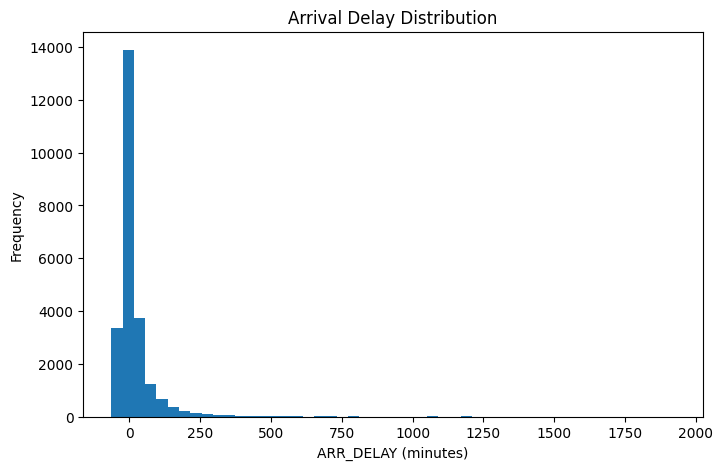

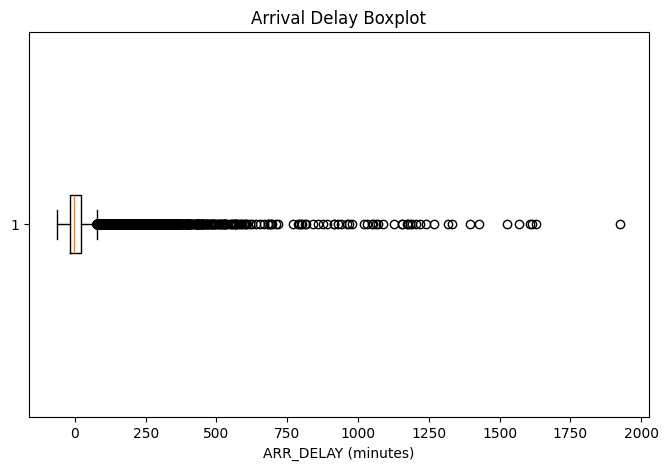

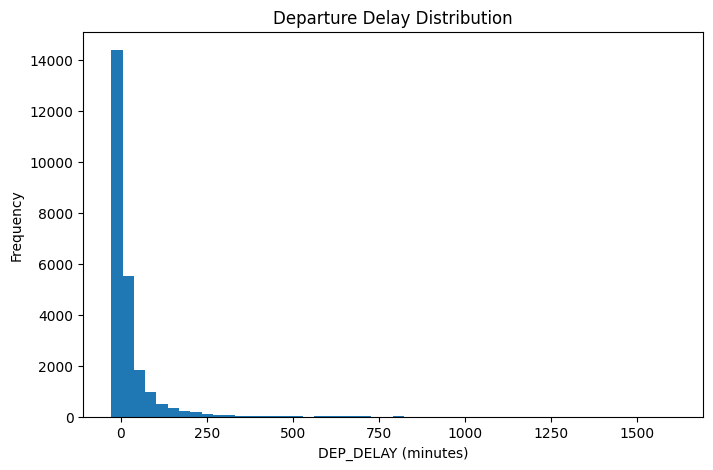

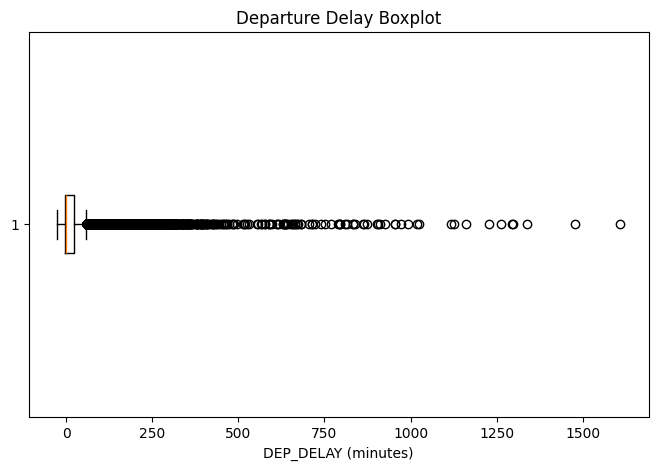

In [11]:
import matplotlib.pyplot as plt

# 1. Arrival histogram
plt.figure(figsize=(8,5))
plt.hist(arr_delay, bins=50)
plt.title("Arrival Delay Distribution")
plt.xlabel("ARR_DELAY (minutes)")
plt.ylabel("Frequency")
plt.show()

# 2. Arrival boxplot
plt.figure(figsize=(8,5))
plt.boxplot(arr_delay, vert=False)
plt.title("Arrival Delay Boxplot")
plt.xlabel("ARR_DELAY (minutes)")
plt.show()

# 3. Departure histogram
plt.figure(figsize=(8,5))
plt.hist(dep_delay, bins=50)
plt.title("Departure Delay Distribution")
plt.xlabel("DEP_DELAY (minutes)")
plt.ylabel("Frequency")
plt.show()

# 4. Departure boxplot
plt.figure(figsize=(8,5))
plt.boxplot(dep_delay, vert=False)
plt.title("Departure Delay Boxplot")
plt.xlabel("DEP_DELAY (minutes)")
plt.show()


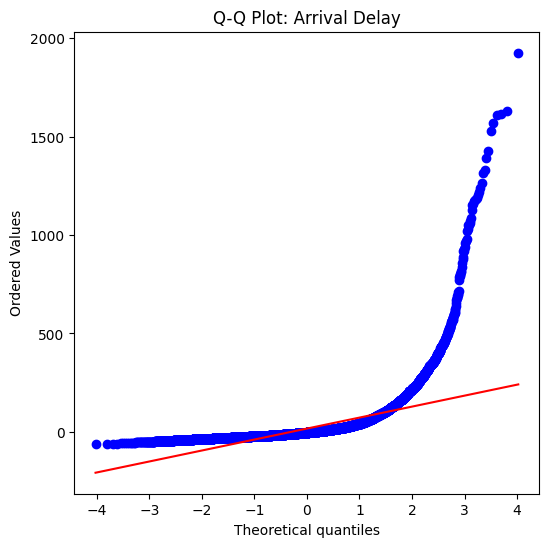

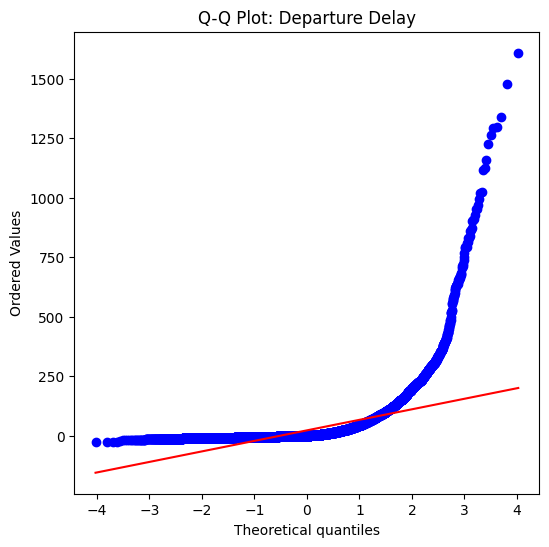

In [12]:
from scipy import stats
import matplotlib.pyplot as plt

# Arrival Q-Q plot
plt.figure(figsize=(6,6))
stats.probplot(arr_delay, dist="norm", plot=plt)
plt.title("Q-Q Plot: Arrival Delay")
plt.show()

# Departure Q-Q plot
plt.figure(figsize=(6,6))
stats.probplot(dep_delay, dist="norm", plot=plt)
plt.title("Q-Q Plot: Departure Delay")
plt.show()

In [13]:
from scipy.stats import levene

stat, p = levene(arr_delay, dep_delay)

print("Levene test statistic:", stat)
print("p-value:", p)

Levene test statistic: 165.24199878000678
p-value: 9.34418524963539e-38


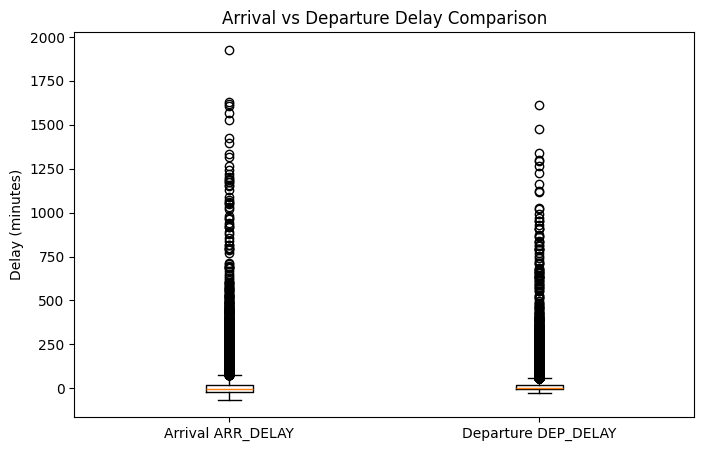

In [14]:
plt.figure(figsize=(8,5))
plt.boxplot([arr_delay, dep_delay], tick_labels=["Arrival ARR_DELAY", "Departure DEP_DELAY"])
plt.title("Arrival vs Departure Delay Comparison")
plt.ylabel("Delay (minutes)")
plt.show()

The dataset includes 24,019 arrival flights and 24,192 departure flights at Chicago O’Hare International Airport (ORD). Departure flights experienced higher average delays (22.50 minutes) than arrivals (16.25 minutes), while arrival delays showed greater variability (SD = 80.71 vs. 67.46). Both delay distributions were highly right-skewed (skewness > 7.5), with substantial extreme values. Levene’s test confirmed a significant difference in variance between the two groups (p < 0.001). These findings highlight the uneven distributions and extreme observations in flight delays, suggesting that model selection and evaluation should account for skewness and outliers. However, descriptive statistics alone cannot establish whether the relationship between scheduled airport traffic volume and flight delays is nonlinear. Further analysis will compare linear and nonlinear regression models to investigate this relationship.

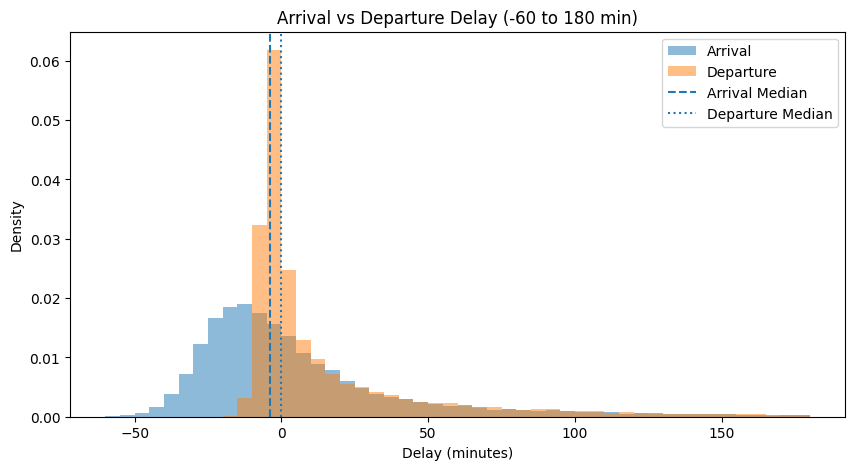

In [15]:

import matplotlib.pyplot as plt
import numpy as np

bins = np.arange(-60, 185, 5)

plt.figure(figsize=(10, 5))

plt.hist(
    arr_delay,
    bins=bins,
    alpha=0.5,
    density=True,
    label="Arrival"
)

plt.hist(
    dep_delay,
    bins=bins,
    alpha=0.5,
    density=True,
    label="Departure"
)

plt.axvline(
    arr_delay.median(),
    linestyle="--",
    label="Arrival Median"
)

plt.axvline(
    dep_delay.median(),
    linestyle=":",
    label="Departure Median"
)

plt.title("Arrival vs Departure Delay (-60 to 180 min)")
plt.xlabel("Delay (minutes)")
plt.ylabel("Density")
plt.legend()
plt.show()
